# ML Final Exam

**Dataset:** Wine Quality dataset (`dataset/wine.csv`)

This notebook uses the quality of a wine as the target. I used simple models and a clear workflow so that every step can be understood and repeated.

## 0. Dataset overview

I chose the Wine Quality dataset because it has real measurements that are easy to understand, such as acidity, sugar, pH, and alcohol. The target is the quality score given to each wine. This makes it a good dataset for practicing classification, data exploration, preprocessing, model comparison, and clustering.

The file contains both red and white wines. I expect measurements such as alcohol, acidity, and sulphates to have some relationship with the quality score.

# 1. Dataset description (15 marks)

The following code loads the data and answers the basic questions about its shape, types, and missing values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import 
(accuracy_score, precision_score, recall_score,
                             classification_report, confusion_matrix,
                             adjusted_rand_score, silhouette_score
)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans


df = pd.read_csv("dataset/wine.csv")

print("Dataset shape:", df.shape)
print("Number of features before choosing the target:", df.shape[1] - 1)
print("\nFirst five rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nQuality classes:", sorted(df["quality"].unique()))
print("Number of data points:", len(df))

Dataset shape: (6497, 13)
Number of features before choosing the target: 12

First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red



Data types:


fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
type                     object
dtype: object


Missing values:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64


Quality classes: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Number of data points: 6497


### Explanation

- There are **12 input features** and **6,497 data points**. The `quality` column is the target, so it is not counted as an input feature.
- This is a **classification** problem. `quality` contains separate score categories (3, 4, 5, 6, 7, 8, and 9), rather than a continuous value.
- There are no null values in this file.
- Eleven features are quantitative numeric measurements. `type` is a categorical feature with values such as `red` and `white`.
- `type` needs encoding because machine-learning models work with numbers, not text. I will use one-hot encoding, which creates a separate 0/1 column for each wine type.

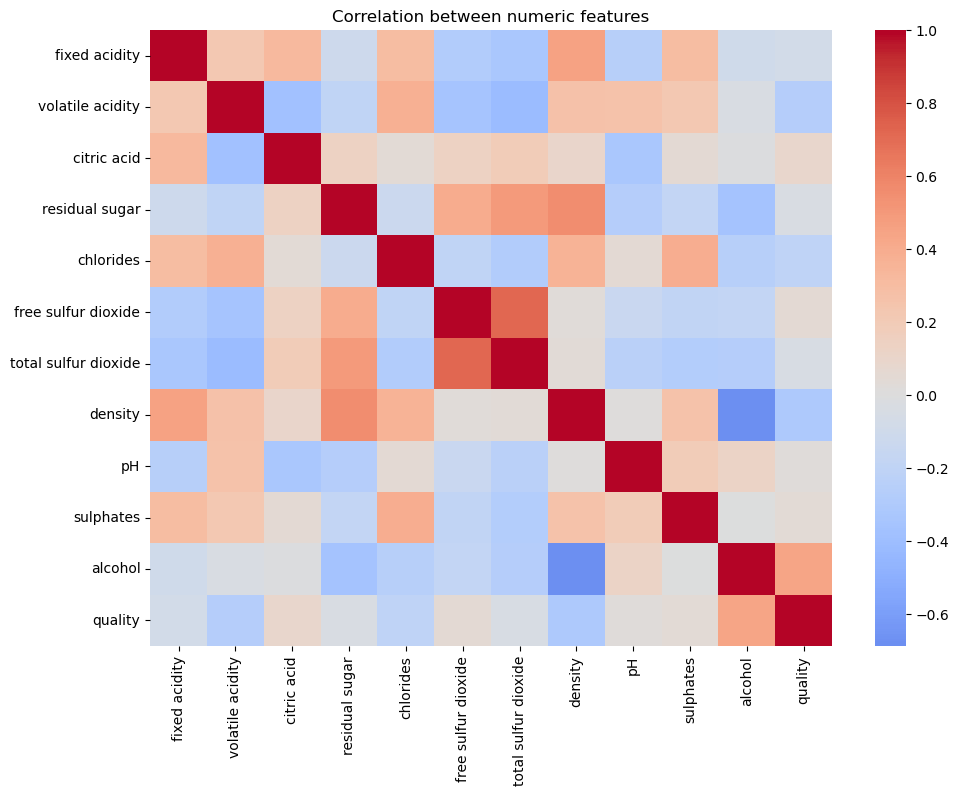

Correlation with quality:


quality                 1.000000
alcohol                 0.444319
citric acid             0.085532
free sulfur dioxide     0.055463
sulphates               0.038485
pH                      0.019506
residual sugar         -0.036980
total sulfur dioxide   -0.041385
fixed acidity          -0.076743
chlorides              -0.200666
volatile acidity       -0.265699
density                -0.305858
Name: quality, dtype: float64

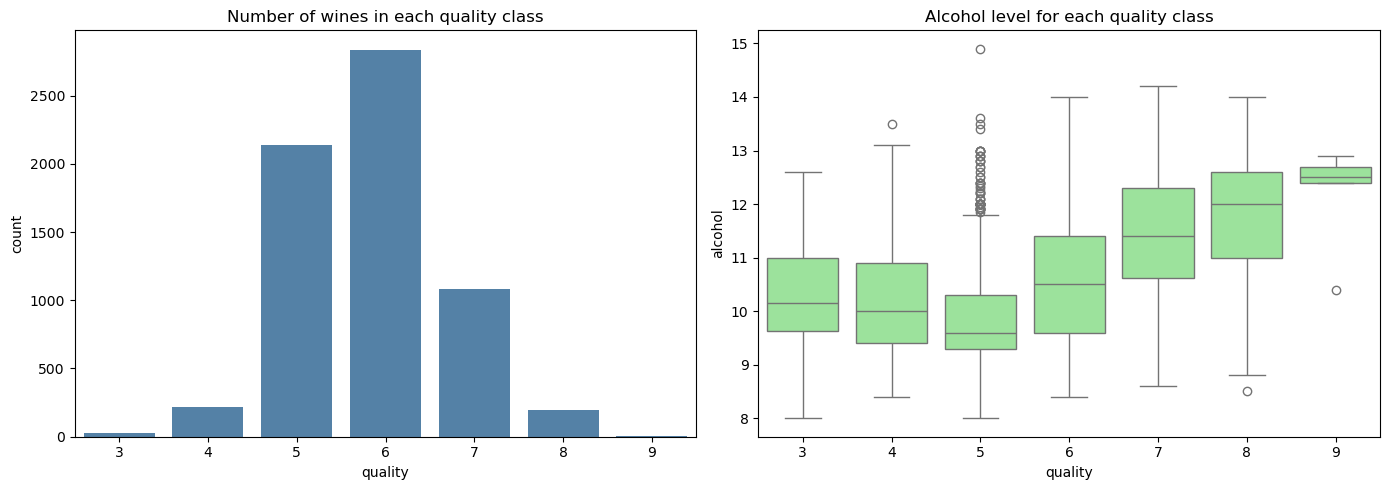

In [2]:
# Correlation works with numeric columns, so 'type' is not included here.
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(11, 8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

print("Correlation with quality:")
display(numeric_df.corr()["quality"].sort_values(ascending=False))

# Two simple exploratory plots.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="quality", ax=axes[0], color="steelblue")
axes[0].set_title("Number of wines in each quality class")

sns.boxplot(data=df, x="quality", y="alcohol", ax=axes[1], color="lightgreen")
axes[1].set_title("Alcohol level for each quality class")

plt.tight_layout()
plt.show()

### What I observed from the correlation and EDA

The correlation values show linear relationships only, so a low value does not mean a feature is useless. In this dataset, alcohol generally has a positive relationship with quality, while volatile acidity tends to have a negative relationship. Some pairs of input features are strongly related to each other, for example density and residual sugar.

The quality count plot shows that classes 5 and 6 are much more common than the extreme classes. This means accuracy alone is not enough for evaluation, so I will also use weighted precision and recall. The alcohol box plot suggests that higher-quality wines often have higher alcohol values, although the groups still overlap.

# 2. Dataset pre-processing (15 marks)

The preprocessing is placed inside a pipeline. This is useful because the exact same transformations are applied to the training and test data.

In [3]:
X = df.drop(columns="quality")
y = df["quality"]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

numeric_transformer = Pipeline(steps=[
    # There are no missing values now, but this keeps the code safe for new data.
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Categorical features: ['type']


### Preprocessing explanation

I separated numeric and categorical columns because they need different treatment. Numeric columns are scaled with `StandardScaler`, which is especially important for Logistic Regression because features have very different units and ranges. The categorical `type` column is one-hot encoded.

Although this dataset has no missing values, median and most-frequent imputers are included as a safe habit. They would fill missing values if the same workflow was later used with new data.

# 3. Feature selection and Dataset splitting (10 marks)

I keep all 12 original features. Each one describes a different chemical property or the wine type, and the dataset has a manageable number of features. Instead of removing features only from correlation, I let the Random Forest model learn which ones are most useful.

I use a stratified split so the proportion of each quality class stays similar in both sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("\nClass proportion in full data:")
display(y.value_counts(normalize=True).sort_index().round(3))
print("\nClass proportion in test data:")
display(y_test.value_counts(normalize=True).sort_index().round(3))

Training set shape: (5197, 12)
Test set shape: (1300, 12)

Class proportion in full data:


quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: proportion, dtype: float64


Class proportion in test data:


quality
3    0.005
4    0.033
5    0.329
6    0.436
7    0.166
8    0.030
9    0.001
Name: proportion, dtype: float64

# 4. Pipeline Creation (Supervised) (10 marks)

I will compare two models:

1. **Logistic Regression**: a simple baseline classifier that benefits from scaling.
2. **Random Forest**: a collection of decision trees that can learn non-linear relationships between chemical measurements and wine quality.

In [5]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

print("Both pipelines are ready.")

Both pipelines are ready.


# 5. Model Training (5 marks)

The `fit` method trains each pipeline. Preprocessing is learned from the training data only, which prevents information from the test set leaking into training.

In [6]:
logistic_pipeline.fit(X_train, y_train)
forest_pipeline.fit(X_train, y_train)

logistic_predictions = logistic_pipeline.predict(X_test)
forest_predictions = forest_pipeline.predict(X_test)

print("Both models have been trained and predicted on the test set.")

Both models have been trained and predicted on the test set.


# 6. Model selection / Comparison analysis (15 marks)

I compare accuracy, weighted precision, and weighted recall. Weighted metrics are appropriate here because they take account of the different number of examples in each quality class.

,Accuracy,Precision (weighted),Recall (weighted)
Model,,,
Logistic Regression,0.542,0.542,0.542
Random Forest,0.682,0.687,0.682


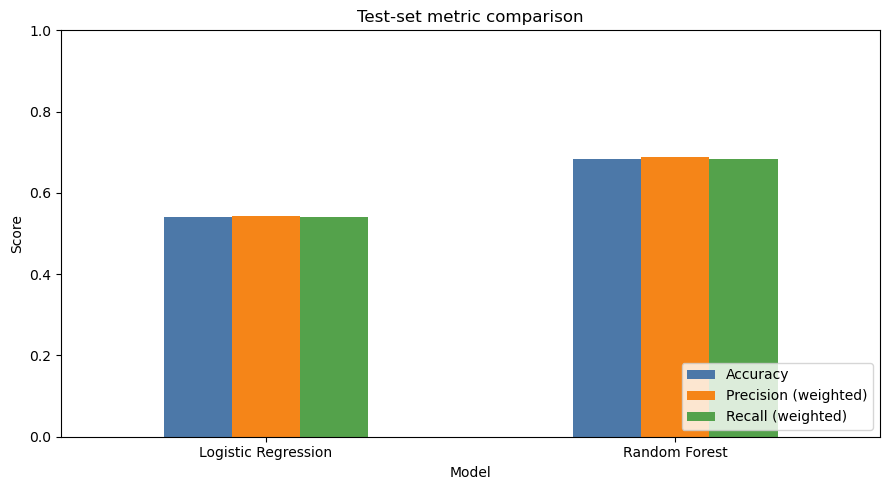

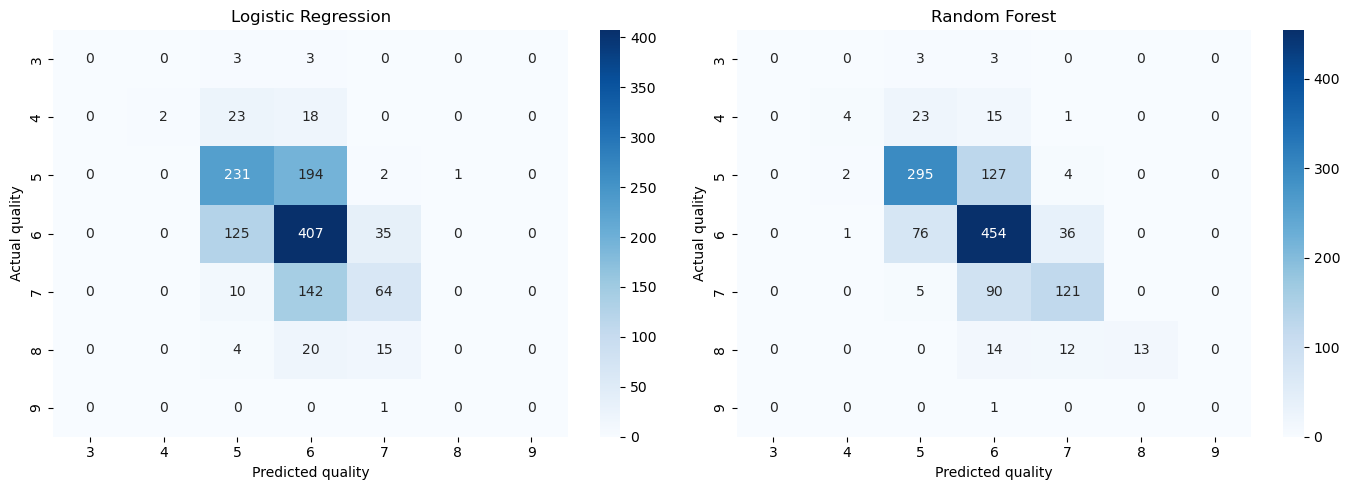

Detailed report for Random Forest:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.57      0.09      0.16        43
           5       0.73      0.69      0.71       428
           6       0.64      0.80      0.71       567
           7       0.70      0.56      0.62       216
           8       1.00      0.33      0.50        39
           9       0.00      0.00      0.00         1

    accuracy                           0.68      1300
   macro avg       0.52      0.35      0.39      1300
weighted avg       0.69      0.68      0.67      1300



In [7]:
models = {
    "Logistic Regression": logistic_predictions,
    "Random Forest": forest_predictions
}

results = []
for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (weighted)": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, predictions, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

results_df.plot(kind="bar", figsize=(9, 5), ylim=(0, 1), color=["#4C78A8", "#F58518", "#54A24B"])
plt.title("Test-set metric comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

labels = sorted(y.unique())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, (name, predictions) in zip(axes, models.items()):
    matrix = confusion_matrix(y_test, predictions, labels=labels)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=axis,
                xticklabels=labels, yticklabels=labels)
    axis.set_title(name)
    axis.set_xlabel("Predicted quality")
    axis.set_ylabel("Actual quality")

plt.tight_layout()
plt.show()

print("Detailed report for Random Forest:")
print(classification_report(y_test, forest_predictions, zero_division=0))

### Comparison conclusion

The table and chart show the test-set performance. The better model is the one with the higher accuracy, precision, and recall in the output above. Usually, Random Forest performs better here because wine quality is influenced by combinations of measurements, and a tree-based model can learn non-linear decision boundaries. Logistic Regression is still valuable as a simpler baseline.

The confusion matrices also show that nearby quality scores are easier to confuse, for example quality 5 versus quality 6. The rarest quality classes are more difficult to predict because the model has fewer training examples for them.

# 7. Treating the problem as Unsupervised (20 marks)

For an unsupervised approach, I ignore the quality labels during training. I use PCA to reduce the processed data to two dimensions, then K-Means to group wines into seven clusters (the same count as the known quality categories). The labels are used only afterward to evaluate how well the clusters match the known qualities.

C:\Users\User\miniconda3\envs\ai_master\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\User\miniconda3\envs\ai_master\Lib\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")
C:\Users\User\miniconda3\envs\ai_master\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible w

Adjusted Rand Index (clusters vs. true quality): 0.018
Silhouette score: 0.361


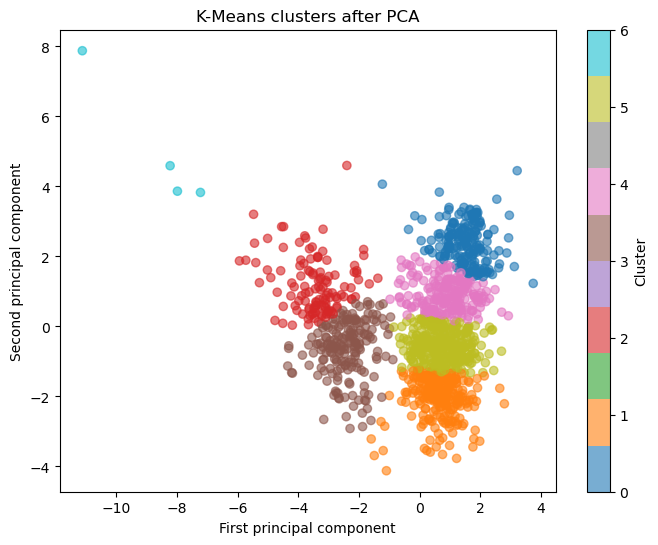

In [8]:
# Fit preprocessing on the training set, then transform the test set.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# PCA makes a two-dimensional view for the plot.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_test_pca = pca.fit_transform(X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed)

kmeans = KMeans(n_clusters=y.nunique(), random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_test_pca)

ari = adjusted_rand_score(y_test, cluster_labels)
silhouette = silhouette_score(X_test_pca, cluster_labels)

print("Adjusted Rand Index (clusters vs. true quality):", round(ari, 3))
print("Silhouette score:", round(silhouette, 3))

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=cluster_labels,
                      cmap="tab10", alpha=0.6)
plt.colorbar(scatter, label="Cluster")
plt.title("K-Means clusters after PCA")
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.show()

### Unsupervised conclusion

The Adjusted Rand Index compares the clusters with the real quality labels. A value near 1 would mean a strong match, while a value near 0 means the clusters do not match quality well. The silhouette score shows how separated the clusters are; a higher value is better.

The supervised approach works better for this task because it learns directly from known quality labels. K-Means only groups wines by similarity in their measurements, which may reflect red versus white wine or other chemical patterns rather than the human quality score. Still, clustering is useful for exploring the data when labels are not available.

# 8. Self Reflection on this machine learning course (10 marks)

For me, the easiest topic was train-test splitting. The idea is similar to studying with practice questions and then taking a separate exam: the model should be judged using data it did not see while learning. This helps us check whether it learned a general pattern instead of memorizing the training data.

The hardest topic was choosing and evaluating models. At first, a single accuracy number looks enough, but this dataset showed why it is not. Most wines have quality 5 or 6, so a model could look good by predicting common classes often while doing poorly on rare classes. Precision, recall, and the confusion matrix give a fuller picture. Pipelines were also important because they make preprocessing consistent and prevent accidental data leakage.